# Notebook 12: Significance, Scaling and Synthesis

Notebooks 10 and 11 report the main comparisons as means across seeds. This notebook
tests the statistical significance of those differences, examines how training cost
changes with dataset size, and brings the main results together.

Three parts:

1. **Significance testing.** Models are compared using the per-user scores saved during
   the earlier experiments. With tens of thousands of paired observations, small
   differences can produce very low p-values, so effect sizes are reported alongside
   significance tests.

2. **Scaling.** The nested subsets created in Notebook 05 are used to measure how
   training cost changes as the interaction graph grows. Cost per epoch is measured
   across all three subsets, with full training performed where the compute budget
   allows.

3. **Synthesis.** The main results are combined into the final comparison tables and
   figures used in the dissertation.

No models are trained here except for the scaling experiments; the remaining sections
use results saved by the earlier notebooks.

## 1. Imports and configuration

In [2]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import evaluation as ev
from src import features as ft
from src import graph as gr
from src import models as md
from src import training as tr

SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features_earliest"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
CACHE = RESULTS_DIR / "12_scaling"
CACHE.mkdir(parents=True, exist_ok=True)

PROTOCOLS = ["last_out", "timestamp"]
SEEDS = [42, 1, 2]
SEED = SEEDS[0]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DIM, LR, BATCH, SAMPLING, EPOCHS = 32, 1e-3, 8192, "user", 300

# where each notebook wrote its per-user scores
PER_USER = {
    "10": RESULTS_DIR / "10_final",
    "11": RESULTS_DIR / "11_final",
    "11_mf": RESULTS_DIR / "11_runs",
}

torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"device: {DEVICE}")

device: cuda


## 2. Significance testing

The same evaluation users appear in the same order across all runs, so models can be
compared using paired per-user scores. This accounts for differences in how difficult
individual users are to predict.

The Wilcoxon signed-rank test is used instead of a paired t-test because per-user
NDCG@10 is heavily zero-inflated and not normally distributed.

Significance tests use seed 42 for all models. Using seed-averaged scores would be
problematic because the models were run with different numbers of seeds, which can
change the number of users receiving small non-zero scores. 

With tens of thousands of paired users, even small differences can produce very low
p-values. Win rates and effect sizes are therefore reported alongside the significance
tests and given more weight when interpreting the results.

In [3]:
def per_user_10(model, protocol, seeds=None, metric="ndcg@10"):
    seeds = seeds or (BPR_SEEDS if model == "BPR-MF" else SEEDS)
    return np.mean([np.load(PER_USER["10"] / f"{model}_{protocol}_s{s}.npz")[metric]
                    for s in seeds], axis=0)


def per_user_11(encoder, protocol, seeds=SEEDS, metric="ndcg@10"):
    return np.mean([np.load(PER_USER["11"] / f"LightGCN_{encoder}_{protocol}_s{s}.npz")[metric]
                    for s in seeds], axis=0)


def per_user_mf(protocol, reg, seeds=SEEDS, metric="ndcg@10"):
    return np.mean([np.load(PER_USER["11_mf"] / f"MF_blair_{protocol}_reg{reg:g}_s{s}_test.npz")[metric]
                    for s in seeds], axis=0)


def per_user_08(model, protocol, metric="ndcg@10"):
    with open(RESULTS_DIR / "08_baselines_per_user.json") as fh:
        store = json.load(fh)
    return np.asarray(store[f"{protocol}|{model}"][metric])

In [4]:
BPR_SEEDS = [42, 1, 2, 3, 4]

In [5]:
for label, arr in [
    ("NB10 LightGCN last_out", per_user_10("LightGCN", "last_out")),
    ("NB10 BPR-MF last_out", per_user_10("BPR-MF", "last_out")),
    ("NB11 LightGCN+blair last_out", per_user_11("blair", "last_out")),
    ("NB11 MF+blair last_out", per_user_mf("last_out", 0.10)),
]:
    print(f"{label:<32} shape {arr.shape}  mean {arr.mean():.5f}")

with open(RESULTS_DIR / "08_baselines_per_user.json") as fh:
    print("\nNotebook 08 keys:", list(json.load(fh).keys()))

NB10 LightGCN last_out           shape (50000,)  mean 0.00812
NB10 BPR-MF last_out             shape (50000,)  mean 0.00640
NB11 LightGCN+blair last_out     shape (50000,)  mean 0.00864
NB11 MF+blair last_out           shape (50000,)  mean 0.00574

Notebook 08 keys: ['last_out|Popularity', 'timestamp|Popularity', 'last_out|ItemKNN', 'timestamp|ItemKNN', 'last_out|BPR-MF', 'timestamp|BPR-MF']


In [ ]:
def compare(a, b, name_a, name_b, protocol):
    """Paired comparison of two models' per-user scores."""
    diff = a - b
    p = stats.wilcoxon(a, b).pvalue if np.any(diff != 0) else 1.0
    decided = diff != 0

    return {
        "protocol": protocol, "A": name_a, "B": name_b,
        "mean A": a.mean(), "mean B": b.mean(),
        "relative": a.mean() / b.mean() - 1,
        "A wins": (diff > 0).sum(),
        "B wins": (diff < 0).sum(),
        "tied": (~decided).sum(),
        "p": p,
    }


# Paired tests use seed 42 only

S = [SEED]

comparisons = pd.DataFrame([
    # Notebook 10: the headline comparison and its reversal
    compare(per_user_10("LightGCN", "last_out", seeds=S),
            per_user_10("BPR-MF", "last_out", seeds=S),
            "LightGCN", "BPR-MF", "last_out"),
    compare(per_user_10("BPR-MF", "timestamp", seeds=S),
            per_user_10("LightGCN", "timestamp", seeds=S),
            "BPR-MF", "LightGCN", "timestamp"),
    compare(per_user_08("ItemKNN", "last_out"),
            per_user_10("LightGCN", "last_out", seeds=S),
            "ItemKNN", "LightGCN", "last_out"),

        # Notebook 11: metadata helps the graph model, at matched regularisation
    compare(per_user_11("blair", "last_out", seeds=S),
            per_user_11("none", "last_out", seeds=S),
            "LightGCN+BLaIR", "LightGCN", "last_out"),
    compare(per_user_11("blair", "timestamp", seeds=S),
            per_user_11("none", "timestamp", seeds=S),
            "LightGCN+BLaIR", "LightGCN", "timestamp"),

    # Notebook 11: and hurts matrix factorisation
    compare(per_user_mf("last_out", 0.10, seeds=S),
            per_user_10("BPR-MF", "last_out", seeds=S),
            "BPR-MF+BLaIR", "BPR-MF", "last_out"),
    compare(per_user_mf("timestamp", 0.15, seeds=S),
            per_user_10("BPR-MF", "timestamp", seeds=S),
            "BPR-MF+BLaIR", "BPR-MF", "timestamp"),
])

comparisons.to_csv(RESULTS_DIR / "12_significance.csv", index=False)

show = comparisons.copy()
show["relative"] = show["relative"].map("{:+.1%}".format)
show["p"] = show["p"].map(lambda v: f"{v:.2e}")
print(show.to_string(index=False, float_format="%.5f"))

 protocol              A        B  mean A  mean B relative  A wins  B wins  tied        p
 last_out       LightGCN   BPR-MF 0.00811 0.00693   +17.0%     637     408 48955 5.82e-05
timestamp         BPR-MF LightGCN 0.00497 0.00179  +178.0%     592     235 49173 2.16e-41
 last_out        ItemKNN LightGCN 0.00948 0.00811   +17.0%     693     603 48704 2.40e-04
 last_out LightGCN+BLaIR LightGCN 0.00872 0.00770   +13.3%     546     414 49040 5.91e-05
timestamp LightGCN+BLaIR LightGCN 0.00237 0.00144   +65.0%     350     219 49431 3.46e-11
 last_out   BPR-MF+BLaIR   BPR-MF 0.00594 0.00693   -14.2%     403     442 49155 2.02e-04
timestamp   BPR-MF+BLaIR   BPR-MF 0.00457 0.00497    -8.1%     478     296 49226 7.78e-01


Most comparisons are statistically significant, with the exception of BPR-MF with
metadata under the timestamp protocol. Around 49,000 of the 50,000 users are tied in
each comparison, meaning that the differences are driven by a relatively small fraction
of evaluation users.

The timestamp comparison for BPR-MF with and without metadata is not significant at
seed 42 (p = 0.78), so the same comparison is checked across the other available seeds.

In [8]:
robustness = pd.DataFrame([
    compare(per_user_mf("timestamp", 0.15, seeds=[s]),
            per_user_10("BPR-MF", "timestamp", seeds=[s]),
            "BPR-MF+BLaIR", "BPR-MF", f"seed {s}")
    for s in SEEDS
])
show = robustness[["protocol", "mean A", "mean B", "relative", "A wins", "B wins", "p"]].copy()
show = show.rename(columns={"protocol": "seed"})
show["relative"] = show["relative"].map("{:+.1%}".format)
show["p"] = show["p"].map(lambda v: f"{v:.2e}")
print(show.to_string(index=False, float_format="%.5f"))

   seed  mean A  mean B relative  A wins  B wins        p
seed 42 0.00457 0.00497    -8.1%     478     296 7.78e-01
 seed 1 0.00406 0.00445    -8.7%     145     270 5.09e-08
 seed 2 0.00402 0.00419    -4.0%     371     479 1.92e-01


A = BPR-MF+BLaIR

B = BPR-MF

Comparing BPR-MF with BLaIR against BPR-MF alone, metadata gives a lower mean NDCG@10 in
all three seeds, but the difference is statistically significant only for seed 1. The
direction is consistent; the per-user evidence is not.

The timestamp result should therefore be treated as a negative trend rather than an
established effect, which is weaker than the leave-last-out result where the decrease is
significant.

In [ ]:
# Metadata paired tests 
metadata_tests_table = comparisons[comparisons["A"].str.contains("BLaIR")].copy()
metadata_tests_table["comparison"] = metadata_tests_table["A"] + " vs " + metadata_tests_table["B"]
metadata_tests_table = metadata_tests_table[["comparison", "protocol", "relative",
                       "A wins", "B wins", "tied", "p"]]

print("Table: Paired per-user tests of metadata effects\n")
print(metadata_tests_table.to_string(index=False))
print("\nWilcoxon signed-rank on per-user NDCG@10, seed 42, matched regularisation.")
print("Seed-42 percentages differ from the three-seed matched means in Notebook 11.")

Table: Paired per-user tests of metadata effects

                comparison  protocol  relative  A wins  B wins  tied            p
LightGCN+BLaIR vs LightGCN  last_out  0.132836     546     414 49040 5.905513e-05
LightGCN+BLaIR vs LightGCN timestamp  0.649796     350     219 49431 3.463123e-11
    BPR-MF+BLaIR vs BPR-MF  last_out -0.142028     403     442 49155 2.020275e-04
    BPR-MF+BLaIR vs BPR-MF timestamp -0.081276     478     296 49226 7.780973e-01

Wilcoxon signed-rank on per-user NDCG@10, seed 42, matched regularisation.
Seed-42 percentages differ from the three-seed matched means in Notebook 11.


## 3. Scaling

Notebook 05 built three nested subsets. Every experiment so far used the smallest, so
this section asks how the models behave as the data grows.

### 3.1 Training cost

Each training batch propagates over the full graph, while the number of batches also
increases with dataset size. LightGCN's cost per epoch is therefore expected to grow
faster than linearly.

Each model is timed for three epochs on each subset, without evaluation.

In [13]:
SCALING_SUBSETS = ["small", "medium", "full"]


def probe_subset(subset, protocol="last_out", epochs=3):
    base = SUBSETS_DIR / subset
    train = pq.read_table(base / "splits" / protocol / "train.parquet",
                          columns=["user_idx", "item_idx"]).to_pandas()
    n_users = len(pq.read_table(base / "user_mapping.parquet"))
    n_items = len(pq.read_table(base / "item_mapping.parquet"))
    n_nodes = n_users + n_items

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    edge_index = gr.build_edge_index(train, n_users, n_items)
    adjacency = gr.normalised_adjacency(edge_index, n_nodes,
                                        device=DEVICE).to_sparse_csr()
    graph_seconds = time.time() - t0

    row = {"subset": subset, "users": n_users, "items": n_items,
           "interactions": len(train), "nodes": n_nodes,
           "edges": edge_index.shape[1], "graph_build_s": round(graph_seconds, 1)}

    builders = {
        "LightGCN": lambda: md.LightGCN(n_users, n_items, dim=DIM, seed=SEED,
                                        adjacency=adjacency, n_layers=3),
        "BPR-MF": lambda: md.MatrixFactorization(n_users, n_items, DIM, SEED),
    }
    for name, build in builders.items():
        out = tr.train_bpr(build(), train, n_items, evaluator=None, epochs=epochs,
                           batch_size=BATCH, learning_rate=LR, l2_reg=1e-3,
                           sampling=SAMPLING, device=DEVICE, seed=SEED, verbose=False)
        row[f"{name} s/epoch"] = round(out["history"]["seconds"].mean(), 2)
        del out
        torch.cuda.empty_cache()

    row["peak GB"] = round(torch.cuda.max_memory_allocated() / 1e9, 1)

    del edge_index, adjacency, train
    torch.cuda.empty_cache()
    return row


rows = []
for subset in SCALING_SUBSETS:
    try:
        rows.append(probe_subset(subset))
        print(f"{subset}: {rows[-1]}", flush=True)
    except torch.cuda.OutOfMemoryError:
        print(f"{subset}: out of memory", flush=True)
        torch.cuda.empty_cache()

scaling_probe = pd.DataFrame(rows)
scaling_probe.to_csv(RESULTS_DIR / "12_scaling_probe.csv", index=False)

for model in ["LightGCN", "BPR-MF"]:
    scaling_probe[f"{model} 300ep (h)"] = (
        scaling_probe[f"{model} s/epoch"] * 300 / 3600).round(1)

scaling_probe

c:\Projects\gnn-recommender-dissertation\src\graph.py:78: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  adj = torch.sparse_coo_tensor(
C:\Users\xhani\AppData\Local\Temp\ipykernel_19472\3835773034.py:16: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  device=DEVICE).to_sparse_csr()
c:\Projects\gnn-recommender-dissertation\src\training.py:65: Us

small: {'subset': 'small', 'users': 258597, 'items': 105298, 'interactions': 1829582, 'nodes': 363895, 'edges': 3659164, 'graph_build_s': 0.5, 'LightGCN s/epoch': np.float64(6.88), 'BPR-MF s/epoch': np.float64(0.84), 'peak GB': 0.9}
medium: {'subset': 'medium', 'users': 676170, 'items': 211842, 'interactions': 4945119, 'nodes': 888012, 'edges': 9890238, 'graph_build_s': 0.2, 'LightGCN s/epoch': np.float64(49.98), 'BPR-MF s/epoch': np.float64(4.65), 'peak GB': 2.3}
full: {'subset': 'full', 'users': 1641026, 'items': 368228, 'interactions': 12191484, 'nodes': 2009254, 'edges': 24382968, 'graph_build_s': 0.5, 'LightGCN s/epoch': np.float64(303.41), 'BPR-MF s/epoch': np.float64(19.0), 'peak GB': 5.4}


,subset,users,items,interactions,nodes,edges,graph_build_s,LightGCN s/epoch,BPR-MF s/epoch,peak GB,LightGCN 300ep (h),BPR-MF 300ep (h)
0,small,258597,105298,1829582,363895,3659164,0.5,6.88,0.84,0.9,0.6,0.1
1,medium,676170,211842,4945119,888012,9890238,0.2,49.98,4.65,2.3,4.2,0.4
2,full,1641026,368228,12191484,2009254,24382968,0.5,303.41,19.00,5.4,25.3,1.6


LightGCN's cost per epoch rises from 6.9 to 50.0 to 303.4 seconds as the number of
interactions grows from 1.8M to 4.9M to 12.2M, showing roughly quadratic growth. BPR-MF scales much more slowly, and the
per-epoch cost gap widens from about 8x on the small subset to 16x on the full subset.

Peak GPU memory reaches only 5.4 GB on the full subset, so the main constraint for
LightGCN at this scale is training time rather than memory.

### 3.2 Performance at larger scale

The scaling study also tests whether model ordering changes as the dataset grows.
ItemKNN, LightGCN and BPR-MF are compared on the `small` and `medium` subsets under
leave-last-out using one seed. BPR-MF is additionally trained on `full` to demonstrate
its feasibility at twelve million interactions.

Hyperparameters are carried over from `small` rather than fully re-tuned. A partial
BPR-MF check on `medium` finds that re-tuning improves NDCG@10 by 5.4%, so the
fixed-hyperparameter comparison slightly overstates the widening performance gap.
Only leave-last-out is used because the models are closest under this protocol, giving
scale the greatest opportunity to change their ordering.

In [2]:
from src import baselines as bl

SCALING_CONFIG = {
    "LightGCN": {"l2_reg": 3e-3, "n_layers": 3, "eval_every": 10, "patience": 10},
    "BPR-MF":   {"l2_reg": 0.10, "eval_every": 2, "patience": 50},
}
ITEMKNN_SHRINKAGE = 200.0
DIM, EPOCHS, BATCH, LR, SAMPLING = 32, 300, 8192, 1e-3, "user"

def load_subset(subset, protocol="last_out"):
    base = SUBSETS_DIR / subset
    splits = base / "splits" / protocol
    parts = {name: pq.read_table(splits / f"{name}.parquet",
                                 columns=["user_idx", "item_idx"]).to_pandas()
             for name in ["train", "validation", "test"]}
    return {"n_users": len(pq.read_table(base / "user_mapping.parquet")),
            "n_items": len(pq.read_table(base / "item_mapping.parquet")),
            "eval_users": pq.read_table(
                splits / "eval_users.parquet").to_pandas()["user_idx"].to_numpy(),
            **parts}


def scaling_run(subset, model_name, protocol="last_out", seed=SEED):
    tag = f"{model_name}_{subset}_{protocol}_s{seed}"
    path = CACHE / f"{tag}.json"
    if path.exists():
        with open(path) as fh:
            return {**json.load(fh), "cached": True}

    d = load_subset(subset, protocol)
    n_users, n_items = d["n_users"], d["n_items"]

    test_eval = ev.Evaluator.from_frames(
        ground_truth=d["test"], mask_frames=[d["train"], d["validation"]],
        eval_users=d["eval_users"], n_users=n_users, n_items=n_items,
        k_values=[10, 20], device=DEVICE, batch_users=512)

    t0 = time.time()
    if model_name == "ItemKNN":
        model = bl.ItemKNNRecommender(100, shrinkage=ITEMKNN_SHRINKAGE).fit(
            d["train"], n_users, n_items, verbose=False)
        score_fn, best_epoch = model.score_fn(DEVICE), None
    else:
        cfg = SCALING_CONFIG[model_name]
        probe = ev.Evaluator.from_frames(
            ground_truth=d["validation"], mask_frames=[d["train"]],
            eval_users=d["eval_users"], n_users=n_users, n_items=n_items,
            k_values=[10], device=DEVICE, batch_users=512)
        usable = d["eval_users"][np.diff(probe.truth_indptr)[d["eval_users"]] > 0]
        val_eval = ev.Evaluator.from_frames(
            ground_truth=d["validation"], mask_frames=[d["train"]],
            eval_users=usable, n_users=n_users, n_items=n_items,
            k_values=[10], device=DEVICE, batch_users=512)

        if model_name == "LightGCN":
            edge_index = gr.build_edge_index(d["train"], n_users, n_items)
            adjacency = gr.normalised_adjacency(
                edge_index, n_users + n_items, device=DEVICE).to_sparse_csr()
            model = md.LightGCN(n_users, n_items, dim=DIM, seed=seed,
                                adjacency=adjacency, n_layers=cfg["n_layers"])
        else:
            model = md.MatrixFactorization(n_users, n_items, DIM, seed)

        out = tr.train_bpr(model, d["train"], n_items, evaluator=val_eval,
                           epochs=EPOCHS, batch_size=BATCH, learning_rate=LR,
                           l2_reg=cfg["l2_reg"], sampling=SAMPLING,
                           patience=cfg["patience"], eval_every=cfg["eval_every"],
                           selection_metric="ndcg@10", device=DEVICE, seed=seed,
                           verbose=False)
        score_fn, best_epoch = out["model"].score_fn(), out["best_epoch"]

    means = test_eval.evaluate(score_fn, return_per_user=False)["means"]
    result = {"subset": subset, "model": model_name, "seed": seed,
              "users": n_users, "items": n_items, "interactions": len(d["train"]),
              "best_epoch": best_epoch, "minutes": (time.time() - t0) / 60, **means}

    with open(path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min, ndcg@10 {result['ndcg@10']:.5f}",
          flush=True)

    del d, test_eval
    torch.cuda.empty_cache()
    return result

In [3]:
scaling_results = pd.DataFrame(
    [scaling_run("small", m) for m in ["ItemKNN", "BPR-MF", "LightGCN"]]
    + [scaling_run("medium", m) for m in ["ItemKNN", "BPR-MF", "LightGCN"]]
    + [scaling_run("full", m) for m in ["ItemKNN", "BPR-MF"]]
)
scaling_results.to_csv(RESULTS_DIR / "12_scaling_results.csv", index=False)

print(scaling_results[["subset", "model", "interactions", "ndcg@10",
                       "hit_rate@10", "minutes"]]
      .to_string(index=False, float_format="%.5f"))

c:\Projects\gnn-recommender-dissertation\src\evaluation.py:144: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  user_tensor = torch.as_tensor(users, dtype=torch.long, device=self.device)


  ItemKNN_full_last_out_s42: 0.8 min, ndcg@10 0.00863
subset    model  interactions  ndcg@10  hit_rate@10   minutes
 small  ItemKNN       1829582  0.00948      0.01736   0.18808
 small   BPR-MF       1829582  0.00693      0.01216   2.19493
 small LightGCN       1829582  0.00811      0.01620  30.23105
medium  ItemKNN       4945119  0.00878      0.01636   0.53984
medium   BPR-MF       4945119  0.00447      0.00944   9.80899
medium LightGCN       4945119  0.00705      0.01446 216.38561
  full  ItemKNN      12191484  0.00863      0.01580   0.83012
  full   BPR-MF      12191484  0.00209      0.00416  38.90417


The model ordering is unchanged at 2.7 times the data (1.83M --> 4.95M): ItemKNN remains first, followed
by LightGCN and BPR-MF. NDCG@10 falls for all three as the catalogue grows and the
ranking task becomes harder.

At full scale only BPR-MF and ItemKNN were run. Matrix factorisation remains practical at
12.2 million interactions, completing in 39 minutes, while the estimated cost makes a
comparable LightGCN run impractical within the compute budget. The two do not degrade
alike: ItemKNN falls 9% from small to full while BPR-MF falls 70%, ending 4.1 times
behind it.

In [16]:
def mf_reg_check(subset, l2_reg, protocol="last_out", seed=SEED):
    tag = f"BPR-MF_{subset}_{protocol}_reg{l2_reg:g}_s{seed}"
    path = CACHE / f"{tag}.json"
    if path.exists():
        with open(path) as fh:
            return {**json.load(fh), "cached": True}

    d = load_subset(subset, protocol)
    n_users, n_items = d["n_users"], d["n_items"]

    test_eval = ev.Evaluator.from_frames(
        ground_truth=d["test"], mask_frames=[d["train"], d["validation"]],
        eval_users=d["eval_users"], n_users=n_users, n_items=n_items,
        k_values=[10, 20], device=DEVICE, batch_users=512)

    probe = ev.Evaluator.from_frames(
        ground_truth=d["validation"], mask_frames=[d["train"]],
        eval_users=d["eval_users"], n_users=n_users, n_items=n_items,
        k_values=[10], device=DEVICE, batch_users=512)
    usable = d["eval_users"][np.diff(probe.truth_indptr)[d["eval_users"]] > 0]
    val_eval = ev.Evaluator.from_frames(
        ground_truth=d["validation"], mask_frames=[d["train"]],
        eval_users=usable, n_users=n_users, n_items=n_items,
        k_values=[10], device=DEVICE, batch_users=512)

    t0 = time.time()
    out = tr.train_bpr(md.MatrixFactorization(n_users, n_items, DIM, seed),
                       d["train"], n_items, evaluator=val_eval, epochs=EPOCHS,
                       batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
                       sampling=SAMPLING, patience=50, eval_every=2,
                       selection_metric="ndcg@10", device=DEVICE, seed=seed,
                       verbose=False)

    means = test_eval.evaluate(out["model"].score_fn(), return_per_user=False)["means"]
    result = {"subset": subset, "l2_reg": l2_reg, "best_epoch": out["best_epoch"],
              "minutes": (time.time() - t0) / 60, **means}

    with open(path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min, ndcg@10 {result['ndcg@10']:.5f}",
          flush=True)

    del d, test_eval, val_eval, probe
    torch.cuda.empty_cache()
    return result


mf_reg = pd.DataFrame([mf_reg_check("medium", r) for r in [0.01, 0.03]])
print(mf_reg[["l2_reg", "best_epoch", "ndcg@10", "minutes"]].to_string(index=False))
print("\nreg 0.1 (from the scaling run): 0.00447")

  BPR-MF_medium_last_out_reg0.01_s42: 25.0 min, ndcg@10 0.00408
  BPR-MF_medium_last_out_reg0.03_s42: 26.4 min, ndcg@10 0.00471
 l2_reg  best_epoch  ndcg@10   minutes
   0.01         292 0.004081 25.003101
   0.03         288 0.004707 26.372210

reg 0.1 (from the scaling run): 0.00447


In [ ]:
# Accuracy and training cost across subsets 

import numpy as np, pandas as pd

probe = pd.read_csv(RESULTS_DIR / "12_scaling_probe.csv").set_index("subset")
acc = (pd.read_csv(RESULTS_DIR / "12_scaling_results.csv")
       .pivot(index="subset", columns="model", values="ndcg@10"))

scaling_table = pd.DataFrame({
    "training interactions": probe["interactions"],
    "ItemKNN ndcg@10": acc.get("ItemKNN"),
    "LightGCN ndcg@10": acc.get("LightGCN"),
    "BPR-MF ndcg@10": acc.get("BPR-MF"),
    "LightGCN s/epoch": probe["LightGCN s/epoch"],
    "BPR-MF s/epoch": probe["BPR-MF s/epoch"],
    "cost ratio": probe["LightGCN s/epoch"] / probe["BPR-MF s/epoch"],
    "peak GB": probe["peak GB"],
}).loc[["small", "medium", "full"]]

print("Table: Accuracy and training cost across dataset sizes\n")
print(scaling_table.to_string(na_rep="-", formatters={
    "training interactions": lambda v: f"{v:,}",
    "ItemKNN ndcg@10": lambda v: "-" if pd.isna(v) else f"{v:.6f}",
    "LightGCN ndcg@10": lambda v: "-" if pd.isna(v) else f"{v:.6f}",
    "BPR-MF ndcg@10": lambda v: "-" if pd.isna(v) else f"{v:.6f}",
    "cost ratio": lambda v: f"{v:.1f}x"}))

slope = np.polyfit(np.log(probe["interactions"]),
                   np.log(probe["LightGCN s/epoch"]), 1)[0]
print(f"\nAccuracy: leave-last-out, seed 42. Cost: three-epoch probe, no evaluation.")
print(f"Peak GPU memory is measured for the probe and is not LightGCN-only.")
print(f"Fitted log-log cost exponent for LightGCN: {slope:.3f} over 3 points.")
print(f"LightGCN at full scale was not trained: 300 epochs at "
      f"{probe.loc['full', 'LightGCN s/epoch']:.2f} s/epoch projects to "
      f"{probe.loc['full', 'LightGCN s/epoch'] * 300 / 3600:.1f} h.")

Table: Accuracy and training cost across dataset sizes

       training interactions ItemKNN ndcg@10 LightGCN ndcg@10 BPR-MF ndcg@10  LightGCN s/epoch  BPR-MF s/epoch cost ratio  peak GB
subset                                                                                                                            
small              1,829,582        0.009479         0.008105       0.006928              6.88            0.84       8.2x      0.9
medium             4,945,119        0.008784         0.007055       0.004470             49.98            4.65      10.7x      2.3
full              12,191,484        0.008633                -       0.002092            303.41           19.00      16.0x      5.4

Accuracy: leave-last-out, seed 42. Cost: three-epoch probe, no evaluation.
Peak GPU memory is measured for the probe and is not LightGCN-only.
Fitted log-log cost exponent for LightGCN: 1.996 over 3 points.
LightGCN at full scale was not trained: 300 epochs at 303.41 s/epoch projects to 

### 3.3 Scaling figures

Two figures summarise the scaling results: training cost on log-log axes with a quadratic
reference line, and NDCG@10 against dataset size. Training interactions are used on the
x-axis because the three subsets are not evenly spaced.

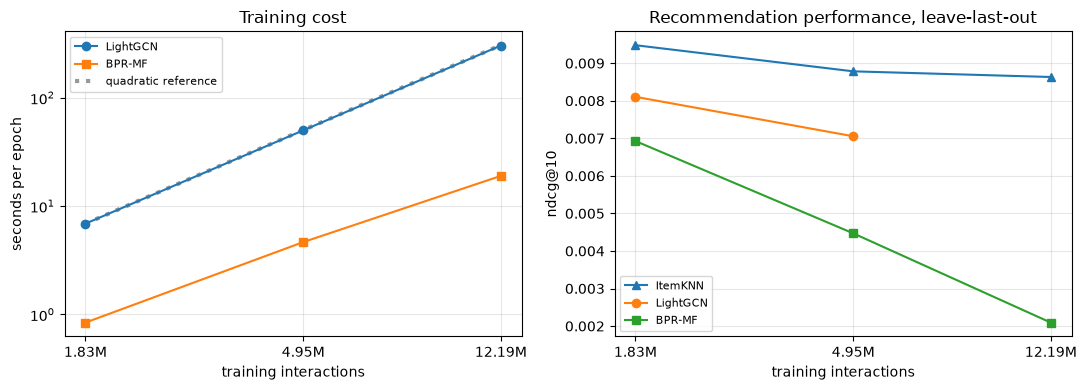

In [7]:
probe = pd.read_csv(RESULTS_DIR / "12_scaling_probe.csv").sort_values("interactions")
acc = pd.read_csv(RESULTS_DIR / "12_scaling_results.csv")
x = probe["interactions"].to_numpy()
labels = [f"{v/1e6:.2f}M" for v in x]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(x, probe["LightGCN s/epoch"].iloc[0] * (x / x[0]) ** 2,
             linestyle=":", color="black", linewidth=3, alpha=0.4,
             label="quadratic reference")
axes[0].plot(x, probe["LightGCN s/epoch"], marker="o", label="LightGCN")
axes[0].plot(x, probe["BPR-MF s/epoch"], marker="s", label="BPR-MF")
axes[0].set(xscale="log", yscale="log", xlabel="training interactions",
            ylabel="seconds per epoch", title="Training cost")

for model, marker in [("ItemKNN", "^"), ("LightGCN", "o"), ("BPR-MF", "s")]:
    d = acc.query("model == @model").sort_values("interactions")
    axes[1].plot(d["interactions"], d["ndcg@10"], marker=marker, label=model)
axes[1].set(xscale="log", xlabel="training interactions", ylabel="ndcg@10",
            title="Recommendation performance, leave-last-out")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.minorticks_off()
    ax.grid(alpha=0.3)

h, l = axes[0].get_legend_handles_labels()
axes[0].legend([h[1], h[2], h[0]], [l[1], l[2], l[0]], fontsize=8)
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_scaling.png", dpi=200)
plt.show()

## 4. Model comparison across protocols

The interaction-only results from Notebooks 08 and 10 are assembled here so the two
protocols can be read side by side. Depth, metadata and cold-start results stay in the
notebooks that produced them. All figures are NDCG@10 on the `small` subset, evaluated
against the full catalogue with the same procedure.

In [4]:

rows = []

# Notebook 08: models that do not train
baselines = pd.read_csv(RESULTS_DIR / "08_baselines.csv", index_col=0)
for label, row in baselines.iterrows():
    protocol, model = [s.strip() for s in label.split("/")]
    if model in ("Popularity", "ItemKNN"):
        rows.append({"protocol": protocol, "model": model, "features": "-",
                     "ndcg@10": row["ndcg@10"], "std": np.nan, "seeds": 1})


def collect(directory, pattern, protocol, model, features, seeds):
    vals = []
    for s in seeds:
        path = directory / pattern.format(protocol=protocol, seed=s)
        if path.exists():
            vals.append(json.load(open(path))["ndcg@10"])
    if vals:
        rows.append({"protocol": protocol, "model": model, "features": features,
                     "ndcg@10": float(np.mean(vals)),
                     "std": float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan,
                     "seeds": len(vals)})


for p in PROTOCOLS:
    # Notebook 10: collaborative only
    for model in ["BPR-MF", "LightGCN", "NGCF", "GraphSAGE"]:
        collect(RESULTS_DIR / "10_final", f"{model}_{{protocol}}_s{{seed}}.json",
                p, model, "-", BPR_SEEDS if model == "BPR-MF" else SEEDS)

    # Notebook 11: with metadata
    collect(RESULTS_DIR / "11_final", "LightGCN_blair_{protocol}_s{seed}.json",
            p, "LightGCN", "BLaIR", SEEDS)
    reg = 0.10 if p == "last_out" else 0.15
    collect(RESULTS_DIR / "11_runs", f"MF_blair_{{protocol}}_reg{reg:g}_s{{seed}}_test.json",
            p, "BPR-MF", "BLaIR", SEEDS)

synthesis = pd.DataFrame(rows).sort_values(["protocol", "ndcg@10"], ascending=[True, False])
synthesis.to_csv(RESULTS_DIR / "12_synthesis.csv", index=False)

for p in PROTOCOLS:
    print(f"\n{p}\n" + "-" * 46)
    print(synthesis.query("protocol == @p")[["model", "features", "ndcg@10", "std", "seeds"]]
          .to_string(index=False, float_format="%.5f"))


last_out
----------------------------------------------
     model features  ndcg@10     std  seeds
   ItemKNN        -  0.00948     NaN      1
  LightGCN    BLaIR  0.00864 0.00011      3
  LightGCN        -  0.00812 0.00007      3
Popularity        -  0.00752     NaN      1
    BPR-MF        -  0.00640 0.00069      5
    BPR-MF    BLaIR  0.00574 0.00034      3
 GraphSAGE        -  0.00425 0.00020      3
      NGCF        -  0.00425 0.00013      3

timestamp
----------------------------------------------
     model features  ndcg@10     std  seeds
    BPR-MF        -  0.00465 0.00040      5
    BPR-MF    BLaIR  0.00422 0.00030      3
  LightGCN    BLaIR  0.00230 0.00007      3
   ItemKNN        -  0.00217     NaN      1
  LightGCN        -  0.00158 0.00020      3
      NGCF        -  0.00150 0.00010      3
 GraphSAGE        -  0.00134 0.00014      3
Popularity        -  0.00124     NaN      1


In [ ]:
# Interaction-only model performance, protocols side by side.

import pandas as pd

syn = pd.read_csv(RESULTS_DIR / "12_synthesis.csv")
io = syn[syn["features"] == "-"].copy()
io["ndcg@10"] = io["ndcg@10"].map(lambda v: f"{v:.6f}")
io["std"] = io["std"].map(lambda v: "-" if pd.isna(v) else f"{v:.6f}")
io["score"] = io.apply(lambda r: f"{r['ndcg@10']} ({r['std']}, n={int(r['seeds'])})"
                       if r["std"] != "-" else f"{r['ndcg@10']} (n=1)", axis=1)

protocol_table = io.pivot(index="model", columns="protocol", values="score")
order = (syn[(syn["features"] == "-") & (syn["protocol"] == "last_out")]
         .sort_values("ndcg@10", ascending=False)["model"])
protocol_table = protocol_table.loc[order]
protocol_table.columns.name = None

print("Table: Interaction-only model performance by evaluation protocol")
print("NDCG@10, mean (sd, seeds)\n")
print(protocol_table.to_string())

ranks = {p: syn[(syn["features"] == "-") & (syn["protocol"] == p)]
              .set_index("model")["ndcg@10"].rank(ascending=False).astype(int)
         for p in PROTOCOLS}
print("\nRank movement (leave-last-out -> timestamp):")
for m in protocol_table.index:
    print(f"  {m:<11} {ranks['last_out'][m]} -> {ranks['timestamp'][m]}")

Table: Interaction-only model performance by evaluation protocol
NDCG@10, mean (sd, seeds)

                            last_out                 timestamp
model                                                         
ItemKNN               0.009479 (n=1)            0.002165 (n=1)
LightGCN    0.008124 (0.000066, n=3)  0.001575 (0.000198, n=3)
Popularity            0.007517 (n=1)            0.001245 (n=1)
BPR-MF      0.006405 (0.000688, n=5)  0.004650 (0.000400, n=5)
GraphSAGE   0.004255 (0.000195, n=3)  0.001343 (0.000143, n=3)
NGCF        0.004246 (0.000130, n=3)  0.001501 (0.000103, n=3)

Rank movement (leave-last-out -> timestamp):
  ItemKNN     1 -> 2
  LightGCN    2 -> 3
  Popularity  3 -> 6
  BPR-MF      4 -> 1
  GraphSAGE   5 -> 5
  NGCF        6 -> 4


In [ ]:
# Spearman rank correlation between the two protocol orderings.


import pandas as pd
from scipy import stats

io = pd.read_csv(RESULTS_DIR / "12_synthesis.csv").query("features == '-'")
order = io.pivot(index="model", columns="protocol", values="ndcg@10")
rho, p = stats.spearmanr(order["last_out"], order["timestamp"])

ranks = order.rank(ascending=False).astype(int)
ranks["places moved"] = ranks["last_out"] - ranks["timestamp"]
print("Protocol ordering, interaction-only methods (rank 1 = best)\n")
print(ranks.sort_values("last_out").to_string())
print(f"\nSpearman rho = {rho:+.3f}  (n = {len(order)}, p = {p:.3f})")
print("Reported as a description of the ordering change, not as a test: with six")
print("methods no coefficient below about 0.89 reaches the 5% level.")

Protocol ordering, interaction-only methods (rank 1 = best)

protocol    last_out  timestamp  places moved
model                                        
ItemKNN            1          2            -1
LightGCN           2          3            -1
Popularity         3          6            -3
BPR-MF             4          1             3
GraphSAGE          5          5             0
NGCF               6          4             2

Spearman rho = +0.314  (n = 6, p = 0.544)
Reported as a description of the ordering change, not as a test: with six
methods no coefficient below about 0.89 reaches the 5% level.


The model ordering changes substantially between protocols. Under leave-last-out,
ItemKNN performs best, while BPR-MF is behind both LightGCN and Popularity. Under
timestamp, BPR-MF moves to first place and Popularity falls to last. NGCF and GraphSAGE
are joint last under leave-last-out and only beat Popularity under timestamp, so neither
is competitive under either protocol.

BPR-MF also shows greater variation across seeds than LightGCN, particularly under
leave-last-out, which is why it is reported over five seeds rather than three.

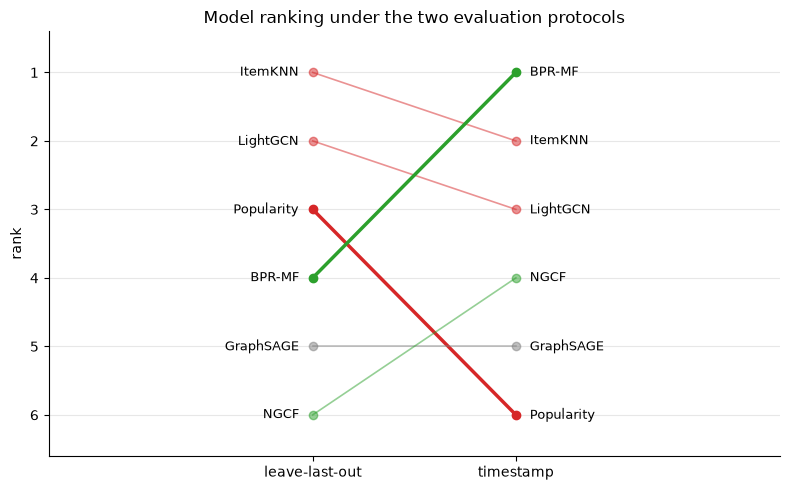

In [ ]:
synthesis["label"] = synthesis.apply(
    lambda r: r["model"] if r["features"] == "-" else f"{r['model']} + {r['features']}",
    axis=1)


plot_df = synthesis[synthesis["features"] == "-"]
n = plot_df["label"].nunique()

ranks = {}
for p in PROTOCOLS:
    ordered = plot_df.query("protocol == @p").sort_values("ndcg@10", ascending=False)
    ranks[p] = {label: i + 1 for i, label in enumerate(ordered["label"])}

fig, ax = plt.subplots(figsize=(8, 5))

for label in ranks["last_out"]:
    y0, y1 = ranks["last_out"][label], ranks["timestamp"][label]
    moved = abs(y1 - y0)
    colour = "tab:green" if y1 < y0 else ("tab:red" if y1 > y0 else "grey")

    ax.plot([0, 1], [y0, y1], marker="o", color=colour,
            linewidth=2.5 if moved >= 3 else 1.2,
            alpha=1.0 if moved >= 3 else 0.5)
    ax.annotate(label, (0, y0), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9)
    ax.annotate(label, (1, y1), xytext=(10, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9)

ax.set(xlim=(-1.3, 2.3), ylim=(n + 0.6, 0.4), xticks=[0, 1],
       xticklabels=["leave-last-out", "timestamp"], ylabel="rank",
       yticks=range(1, n + 1))
ax.set_title("Model ranking under the two evaluation protocols")
ax.grid(alpha=0.3, axis="y")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_protocol_ranking.png", dpi=200)
plt.show()


Thick lines are models that move three or more places. 

## 5. Checks and saved results

The claims of this notebook restated as assertions, including a reproduction check: the
scaling study retrained every model on `small` from scratch, so those results should match
Notebooks 08 and 10.

In [20]:
def sig(a, b, protocol):
    row = comparisons.query("A == @a and B == @b and protocol == @protocol")
    return float(row["p"].iloc[0]), float(row["relative"].iloc[0])


cost_slope = np.polyfit(np.log(probe["interactions"]),
                        np.log(probe["LightGCN s/epoch"]), 1)[0]
small = scaling_results.query("subset == 'small'").set_index("model")["ndcg@10"]

checks = {
    "LightGCN beats BPR-MF under leave-last-out, significantly":
        sig("LightGCN", "BPR-MF", "last_out")[0] < 0.01,
    "BPR-MF beats LightGCN under timestamp, significantly":
        sig("BPR-MF", "LightGCN", "timestamp")[0] < 0.01,
    "ItemKNN beats LightGCN under leave-last-out, significantly":
        sig("ItemKNN", "LightGCN", "last_out")[0] < 0.01,
    "metadata helps LightGCN on both protocols, significantly":
        all(sig("LightGCN+BLaIR", "LightGCN", p)[0] < 0.01 for p in PROTOCOLS),
    "metadata hurts BPR-MF under leave-last-out, significantly":
        sig("BPR-MF+BLaIR", "BPR-MF", "last_out")[0] < 0.01,

    "LightGCN training cost grows quadratically":
        abs(cost_slope - 2.0) < 0.1,
    "LightGCN costs more per epoch than BPR-MF at every size":
        (probe["LightGCN s/epoch"] > probe["BPR-MF s/epoch"]).all(),
    "the cost ratio widens with dataset size":
        (probe["LightGCN s/epoch"] / probe["BPR-MF s/epoch"]).is_monotonic_increasing,
    "model ordering is preserved from small to medium":
        all(scaling_results.query("subset == @s and model != 'ItemKNN' or subset == @s")
            .sort_values("ndcg@10", ascending=False)["model"].tolist()
            == ["ItemKNN", "LightGCN", "BPR-MF"] for s in ["small", "medium"]),

    "scaling study reproduces Notebook 08 ItemKNN on small":
        abs(small["ItemKNN"] - 0.00948) < 1e-5,
    "scaling study reproduces Notebook 10 LightGCN on small":
        abs(small["LightGCN"] - 0.00811) < 1e-5,
    "scaling study reproduces Notebook 10 BPR-MF on small":
        abs(small["BPR-MF"] - 0.00693) < 1e-5,

    "synthesis covers every model on both protocols":
        len(synthesis) == 16,
}

width = max(len(k) for k in checks)
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name:<{width}}")

assert all(checks.values()), [k for k, v in checks.items() if not v]
print(f"\nall {len(checks)} checks passed")
print(f"\nfitted cost exponent: {cost_slope:.3f}")

PASS  LightGCN beats BPR-MF under leave-last-out, significantly 
PASS  BPR-MF beats LightGCN under timestamp, significantly      
PASS  ItemKNN beats LightGCN under leave-last-out, significantly
PASS  metadata helps LightGCN on both protocols, significantly  
PASS  metadata hurts BPR-MF under leave-last-out, significantly 
PASS  LightGCN training cost grows quadratically                
PASS  LightGCN costs more per epoch than BPR-MF at every size   
PASS  the cost ratio widens with dataset size                   
PASS  model ordering is preserved from small to medium          
PASS  scaling study reproduces Notebook 08 ItemKNN on small     
PASS  scaling study reproduces Notebook 10 LightGCN on small    
PASS  scaling study reproduces Notebook 10 BPR-MF on small      
PASS  synthesis covers every model on both protocols            

all 13 checks passed

fitted cost exponent: 1.996


In [21]:
summary = {
    "notebook": "12_significance_scaling_synthesis",
    "significance": {
        "test": "Wilcoxon signed-rank on per-user NDCG@10, paired by user",
        "seeds": "single seed (42) so every model is averaged over the same number of runs",
        "comparisons": comparisons.to_dict(orient="records"),
    },
    "scaling": {
        "subsets": scaling_probe[["subset", "users", "items", "interactions",
                                  "LightGCN s/epoch", "BPR-MF s/epoch"]]
                   .to_dict(orient="records"),
        "cost_exponent_lightgcn": round(float(cost_slope), 3),
        "wall_clock_ratio": {
            r["subset"]: round(
                scaling_results.query("subset == @r['subset'] and model == 'LightGCN'")
                ["minutes"].iloc[0]
                / scaling_results.query("subset == @r['subset'] and model == 'BPR-MF'")
                ["minutes"].iloc[0], 1)
            for _, r in scaling_probe.iterrows() if r["subset"] != "full"
        },
        "results": scaling_results.to_dict(orient="records"),
    },
    "synthesis": synthesis.to_dict(orient="records"),
}

with open(RESULTS_DIR / "12_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

print(json.dumps(summary["scaling"]["wall_clock_ratio"], indent=2))

{
  "small": 13.8,
  "medium": 22.1
}


## Findings

**The headline results are statistically firm.** LightGCN beats matrix factorisation
under leave-last-out (p = 5.8e-05) and matrix factorisation beats LightGCN under the
timestamp protocol (p = 2.2e-41), on paired per-user comparisons. Metadata's benefit to
LightGCN is significant on both protocols; its cost to matrix factorisation is
significant under leave-last-out but not under timestamp, where the mean falls in all
three seeds but the paired test reaches significance in only one.

**97 to 99% of users are tied in every comparison.** Neither model puts anything the
user wanted in their top 10, so every difference in this project is decided by the
remaining few per cent. A reader seeing "+27%" should not imagine a broad effect.

**LightGCN's measured cost per epoch grew roughly with the square of the training-set
size across the three tested subsets.** The fitted exponent is 1.996 over three points
spanning 1.8 to 12.2 million interactions. This describes the measured range on one GPU
and is not a complexity law.

**The cost gap to matrix factorisation widens with scale**: 13.8 times more wall-clock
time on `small`, 22.1 times on `medium`. Matrix factorisation trains on the full 12.2
million interactions in 39 minutes; 300 LightGCN epochs at the measured per-epoch rate
would take roughly 25 hours, a projection rather than an executed run.

**Accuracy falls for all three methods measured at both sizes**, because the catalogue
grows with the data and there are more candidates to rank against. The ordering is
preserved from `small` to `medium` and the gaps widen, though a partial re-tuning of
matrix factorisation suggests holding hyperparameters fixed overstates that widening by
about 5%. The two methods run at full scale do not degrade alike: ItemKNN falls 9% from
`small` to `full` while BPR-MF falls 70%, leaving the neighbourhood baseline 4.1 times
ahead at 12.2 million interactions.

**The model ranking changes substantially between the two protocols.** Among the six
interaction-only methods, matrix factorisation moves from fourth to first, Popularity
from third to last, and ItemKNN from first to second. It is not a reversal: Spearman
between the two orderings is +0.31. Popularity's fall is the clearest signature of the
leakage, since nothing about the model changed, only whether its item counts could
include activity occurring after the test point.


# Generative AI use

AI was used to support code debugging and improve the visualisation of experimental results.